# Optical pooled screens

An optical pooled screen (OPS) delivers a CRISPR library to one dish of cells, images every cell in a few channels,
and reads each cell's guide by in-situ sequencing. One dish holds thousands of knockouts at once. The payoff is a
map: because genes that do the same job in the cell look alike under the microscope, morphology alone rediscovers
the cell's machinery, the ribosome, the proteasome and the spliceosome among it, with no sequence or annotation used.

This page builds to that map on **Aconcagua**, a HeLa screen of 5,299 essential and dependency genes imaged in four
channels: DNA (DAPI), microtubules (alpha-tubulin), DNA damage (gamma-H2AX) and F-actin (phalloidin). It first works
a subset end to end, from a single cell to a gene call, with mantispy, meeting the one problem an OPS has to get
right along the way: the DNA damage that Cas9 causes simply by cutting. It then opens the full published landscape
and shows what morphology recovers.

Two words recur. A **guide** is one CRISPR reagent against one gene; four guides target each gene, and a guide is
the unit that is scored. A **well** is one imaged culture; because the library is pooled, every well holds many
guides, and a guide's wells are its replicates. The data are from Di Bernardo et al., Nat Commun 17, 6997 (2026),
[doi:10.1038/s41467-026-73643-7](https://doi.org/10.1038/s41467-026-73643-7), screened in Funk et al., Cell 185,
4634 (2022), and served through the CZ Biohub OPS Explorer.

In [1]:
import warnings

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pooch
import scanpy as sc

import mantispy as mt

warnings.filterwarnings("ignore")
sc.settings.verbosity = 0
plt.rcParams["figure.dpi"] = 110
SEED = 0

adata = mt.ds.aconcagua()
adata

AnnData object with n_obs × n_vars = 84125 × 1483
    obs: 'Metadata_Plate', 'Metadata_Well', 'Metadata_Guide', 'Metadata_CellCount', 'Metadata_SiteCount', 'Metadata_Gene', 'Metadata_Perturbation', 'Metadata_Control_Type', 'Metadata_Tier', 'Metadata_Control', 'Metadata_Perturbation_Type', 'Metadata_ObjectType', 'Metadata_MitoticFraction'
    var: 'object', 'feature_group', 'feature', 'channel', 'scale', 'angle', 'gray_levels', 'radial_bin', 'params', 'is_feature', 'feature_kind', 'degenerate_scale'
    uns: 'mantispy'
    layers: None (.X)

One row per guide per well: the median of that guide's cells in that well, normalized against the non-targeting
cells of the same well with {func}`~mantispy.pp.normalize`. The subset keeps all 250 non-targeting guides, four
positive controls, 50 strong and 50 weak known hits, and 396 random library genes, each as profiles across 46 wells.

## What the screen sees

Before any profile, the cells. The OPS Explorer publishes example crops of segmented cells, one small OME-Zarr per
cell in four channels. A handful for one gene shows what every feature below is measured from: the nucleus in DNA,
the spindle in tubulin, double-strand breaks in gamma-H2AX, the cell body in actin.

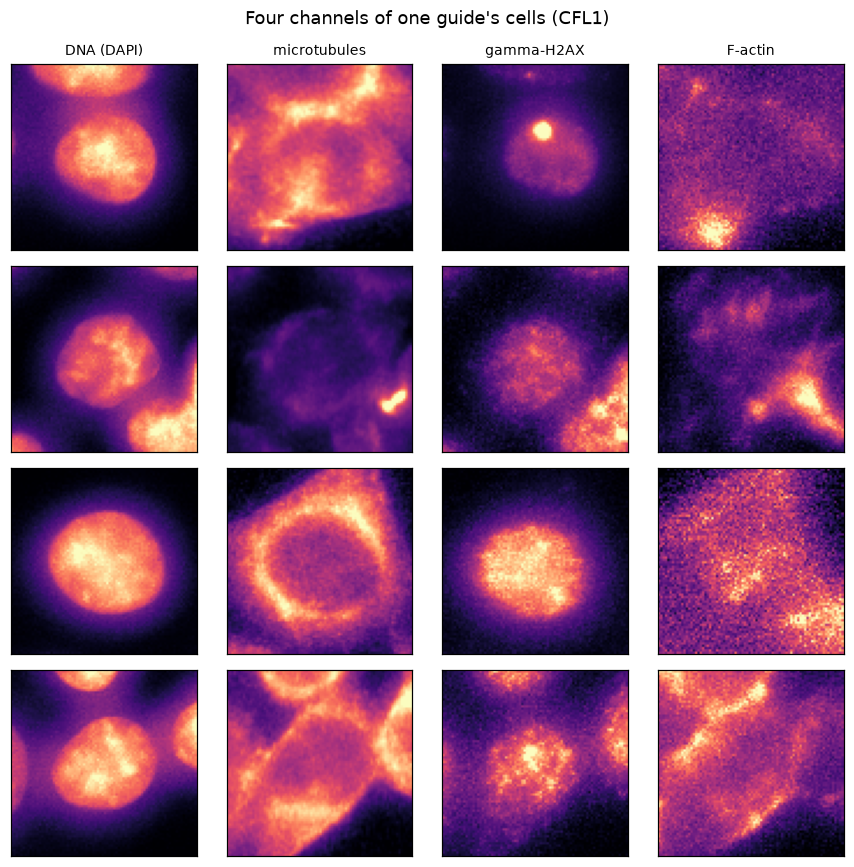

In [2]:
import boto3
import zarr
from botocore import UNSIGNED
from botocore.config import Config

# Example single-cell crops from the OPS Explorer public bucket (anonymous S3). Needs `boto3` and `zarr`.
_S3 = boto3.client("s3", region_name="us-west-2", config=Config(signature_version=UNSIGNED))
_BUCKET = "ops-explorer-public"
CHANNELS = ["DNA (DAPI)", "microtubules", "gamma-H2AX", "F-actin"]
_CROPS = pooch.os_cache("mantispy") / "aconcagua_crops"


def _prefixes(prefix):
    out, token = [], None
    while True:
        extra = {"ContinuationToken": token} if token else {}
        r = _S3.list_objects_v2(Bucket=_BUCKET, Prefix=prefix.rstrip("/") + "/", Delimiter="/", **extra)
        out += [p["Prefix"] for p in r.get("CommonPrefixes", [])]
        if not r.get("IsTruncated"):
            return out
        token = r["NextContinuationToken"]


def example_cells(gene, n=4, phase="interphase", seed=SEED):
    """Return n (4, H, W) crops for a gene, downloaded once and cached locally."""
    base = f"aconcagua/aconcagua/visualizations/{phase}/examples/DAPI_TUBULIN_GH2AX_PHALLOIDIN"
    guide = _prefixes(f"{base}/{gene}")[0].rstrip("/")
    crops = _prefixes(guide)
    picks = np.random.default_rng(seed).choice(len(crops), size=min(n, len(crops)), replace=False)
    images = []
    for i in sorted(picks):
        crop = crops[i].rstrip("/")
        local = _CROPS / crop
        if not (local / "zarr.json").exists():
            local.mkdir(parents=True, exist_ok=True)
            for obj in _S3.list_objects_v2(Bucket=_BUCKET, Prefix=crop + "/")["Contents"]:
                dst = _CROPS / obj["Key"]
                dst.parent.mkdir(parents=True, exist_ok=True)
                _S3.download_file(_BUCKET, obj["Key"], str(dst))
        images.append(np.asarray(zarr.open_group(str(local), mode="r")["0"][:]).squeeze())
    return images


def _stretch(plane):
    lo, hi = np.percentile(plane, [1, 99.5])
    return np.clip((plane.astype(float) - lo) / max(hi - lo, 1), 0, 1)


def show_cells(images, title):
    """Draw each cell as a row of its four channels."""
    fig, axes = plt.subplots(len(images), 4, figsize=(8, 2 * len(images)), squeeze=False)
    for row, img in enumerate(images):
        for col in range(4):
            ax = axes[row, col]
            ax.imshow(_stretch(img[col]), cmap="magma")
            ax.set_xticks([])
            ax.set_yticks([])
            if row == 0:
                ax.set_title(CHANNELS[col], fontsize=9)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


show_cells(example_cells("CFL1"), "Four channels of one guide's cells (CFL1)")

Each row is one cell; each column a channel. Every feature that follows is a summary of images like these.

## The controls move the channel they were chosen for

Before calling anything, a sanity check: the screen's own positive controls should move the channel they were
chosen for. The knockouts of H2AX, TUBB and CFL1 remove or disturb the very protein a stain detects, so each should
shift its feature away from the non-targeting cells. They do, in the expected direction.

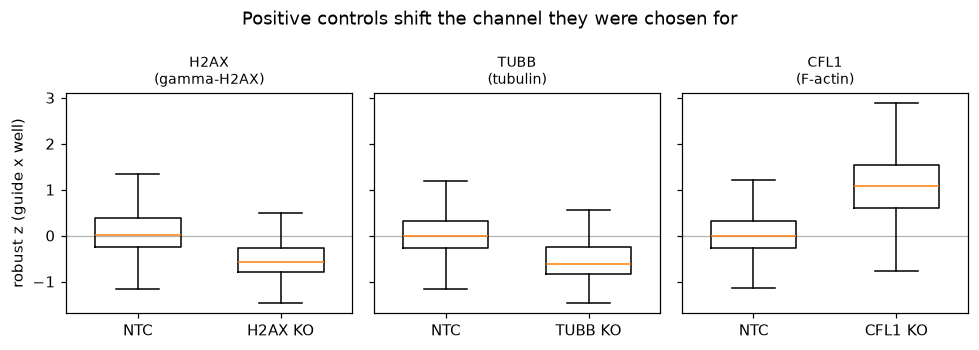

In [3]:
controls = (adata.obs["Metadata_Control_Type"] == "negcon").to_numpy()
checks = {
    "H2AX": ("Nuclei_Intensity_MeanIntensity_GH2AX", "gamma-H2AX"),
    "TUBB": ("Cells_Intensity_MeanIntensity_TUBULIN", "tubulin"),
    "CFL1": ("Cells_Intensity_MeanIntensity_PHALLOIDIN", "F-actin"),
}
fig, axes = plt.subplots(1, 3, figsize=(9, 3.2), sharey=True)
for ax, (gene, (feature, label)) in zip(axes, checks.items(), strict=True):
    values = adata[:, feature].X.ravel()
    ko = values[(adata.obs["Metadata_Gene"] == gene).to_numpy()]
    ntc = values[controls]
    ax.boxplot([ntc, ko], tick_labels=["NTC", f"{gene} KO"], widths=0.6, showfliers=False)
    ax.axhline(0, color="0.7", lw=0.8, zorder=0)
    ax.set_title(f"{gene}\n({label})", fontsize=9)
axes[0].set_ylabel("robust z (guide x well)")
fig.suptitle("Positive controls shift the channel they were chosen for")
fig.tight_layout()
plt.show()

The calling that follows is kept honest in ways we will not dwell on: degenerate features with no spread are dropped
({func}`~mantispy.pp.feature_select`), the subset was drawn so controls and targeting guides carry comparable cell
counts, and each well is normalized against its own non-targeting cells, which leaves no plate or well effect for a
batch correction to remove. With that in place, the one problem specific to a CRISPR screen is next.

## Cas9 cutting is a phenotype of its own

A targeting guide makes Cas9 cut the genome; a non-targeting guide does not. The double-strand break alone raises
gamma-H2AX, whatever gene is cut, so a guide can look active just for cutting. Genes the cells do not express are
the clean test: knocking them out can do nothing, yet they still carry more DNA damage than not cutting at all.
DepMap's expression for HeLa (model ACH-001086) names the unexpressed genes.

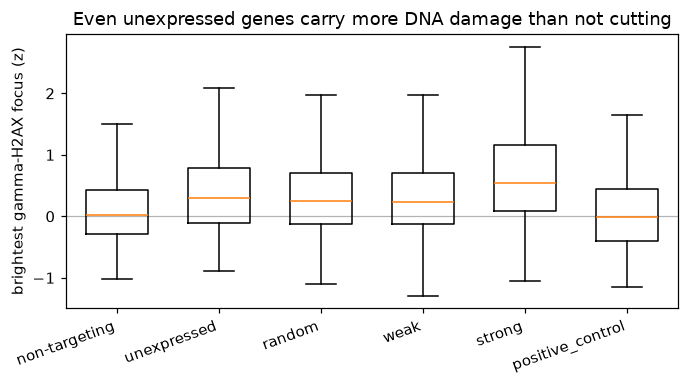

In [4]:
mt.pp.feature_select(adata)
adata = mt.pp.subset_features(adata)

# DepMap 24Q4 expression (CC BY 4.0), fetched from figshare; HeLa is model ACH-001086.
depmap = pooch.retrieve(
    "https://ndownloader.figshare.com/files/51065489",
    known_hash="sha256:2a71dc94110efcc0221eae821bb93a9f03b54bea16f005818911a09d33383d56",
    fname="depmap_24q4_expression.csv",
)
unexpressed = mt.io.unexpressed_genes(depmap, "ACH-001086")
go = adata.obs
foci = "Nuclei_Intensity_MaxIntensity_GH2AX"
kind = np.where(
    go["Metadata_Control_Type"] == "negcon",
    "non-targeting",
    np.where(go["Metadata_Gene"].astype(str).isin(unexpressed), "unexpressed", go["Metadata_Tier"].astype(str)),
)
damage = pd.DataFrame({"z": adata[:, foci].X.ravel(), "kind": kind})
groups = ["non-targeting", "unexpressed", "random", "weak", "strong", "positive_control"]
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.boxplot([damage.loc[damage["kind"] == g, "z"] for g in groups], tick_labels=groups, showfliers=False, widths=0.6)
ax.axhline(0, color="0.7", lw=0.8, zorder=0)
ax.set_ylabel("brightest gamma-H2AX focus (z)")
ax.set_title("Even unexpressed genes carry more DNA damage than not cutting")
plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
fig.tight_layout()
plt.show()

So a non-targeting null answers *does this guide differ from not cutting*. The question a screen asks is *does
losing this gene do anything beyond the cut*, and the unexpressed genes are its null. Pooling each gene's four
guides into a call ({func}`~mantispy.tl.guide_activity`, {func}`~mantispy.tl.aggregate_guides`) and then calibrating
against the unexpressed genes ({func}`~mantispy.tl.empirical_fdr`) separates the two. The non-targeting guides are
split at random so the activity scale is set on one half and the null on the other, never on themselves.

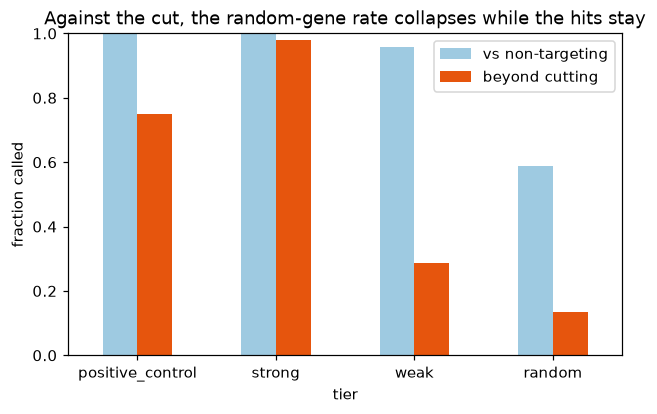

In [5]:
guides = mt.tl.aggregate(adata, by=("Metadata_Guide",), func="median", min_cells=1)
go = guides.obs
ntc = np.sort(go.loc[go["Metadata_Control_Type"] == "negcon", "Metadata_Guide"].astype(str).unique())
roll = np.random.default_rng(SEED).permutation(ntc)
role = dict.fromkeys(roll[:100], "ntc_scale") | dict.fromkeys(roll[100:200], "nontargeting")
role |= {guide: f"PSEUDO{i // 4:02d}" for i, guide in enumerate(roll[200:248])}
assigned = go["Metadata_Guide"].astype(str).map(role)
go["Analysis_Group"] = np.where(assigned.notna(), assigned, go["Metadata_Gene"].astype(str))
guides.X = np.nan_to_num(guides.X)
sc.pp.pca(guides, n_comps=50, random_state=SEED)
mt.tl.guide_activity(guides, reference="ntc_scale", group="Analysis_Group", use_rep="X_pca")
mt.tl.aggregate_guides(
    guides, score="guide_activity", guide="Metadata_Guide", gene="Analysis_Group", control="nontargeting", seed=SEED
)
calls = pd.DataFrame(guides.uns["mantispy"]["gene_aggregation"]).set_index("group").rename_axis("gene")
tier = dict(zip(go["Metadata_Gene"].astype(str), go["Metadata_Tier"].astype(str), strict=True))
calls["tier"] = ["pseudo-gene" if g.startswith("PSEUDO") else tier.get(g, "?") for g in calls.index]
calls["unexpressed"] = calls.index.isin(unexpressed)

genes = calls[calls["tier"] != "pseudo-gene"].copy()
table = ad.AnnData(obs=pd.DataFrame({"gene": genes.index, "score": genes["statistic"].to_numpy()}, index=genes.index))
mt.tl.empirical_fdr(
    table, control_genes=sorted(set(genes.index) & unexpressed), score="score", group="gene", alpha=0.05, criterion="q"
)
beyond = pd.DataFrame(table.uns["mantispy"]["empirical_fdr"]).set_index("group")
genes["beyond_cutting"] = beyond["is_hit"].reindex(genes.index).astype("boolean")
tested = genes[~genes["unexpressed"]]
rates = tested.groupby("tier").agg(
    **{"vs non-targeting": ("is_hit", "mean"), "beyond cutting": ("beyond_cutting", "mean")}
)
rates = rates.reindex(["positive_control", "strong", "weak", "random"]).dropna(how="all")
ax = rates.plot.bar(figsize=(6.5, 3.8), color=["#9ecae1", "#e6550d"], rot=0)
ax.set_ylabel("fraction called")
ax.set_ylim(0, 1)
ax.set_title("Against the cut, the random-gene rate collapses while the hits stay")
ax.legend()
plt.show()

Against the unexpressed null the strong known hits stay (about 98 %) while the random-gene rate falls from about
60 % to about 13 %. The known hits survive because they do something beyond cutting; most random genes do not.
(With only about 30 unexpressed genes the null is coarse, which is why the cutoff is a q-value of 0.05 rather than
anything finer. Measured a different way, most genes have guides that replicate above a permutation null, via
{func}`~mantispy.tl.percent_replicating`.)

## What moved

A call says a gene does something; the features say what. A moderated t-test per feature against the controls
({func}`~mantispy.tl.differential_features`) collapsed by channel ({func}`~mantispy.tl.feature_signature`) gives a
compact fingerprint per gene.

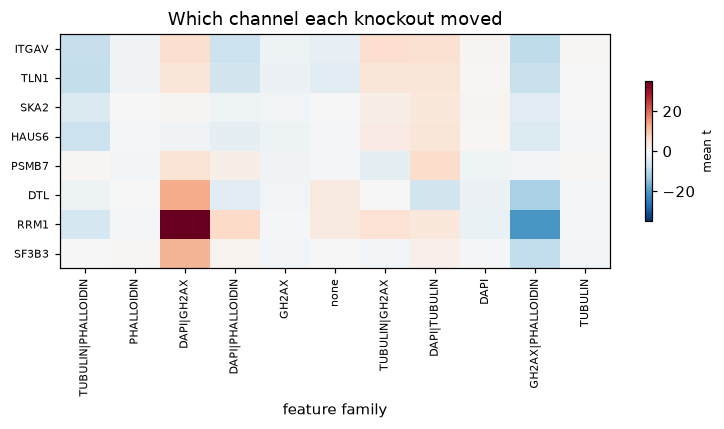

In [6]:
examples = ["RRM1", "DTL", "SKA2", "HAUS6", "ITGAV", "TLN1", "PSMB7", "SF3B3"]
present = [g for g in examples if (adata.obs["Metadata_Gene"].astype(str) == g).any()]
negcon = list(adata.obs.loc[adata.obs["Metadata_Control_Type"] == "negcon", "Metadata_Gene"].astype(str).unique())
sub = adata[adata.obs["Metadata_Gene"].astype(str).isin(present + negcon)].copy()
mt.tl.differential_features(sub, groupby="Metadata_Gene", reference="negcon", block="Metadata_Plate")
sig = mt.tl.feature_signature(sub, key="differential", by=("channel",), statistic="t")
sig = sig[[g for g in present if g in sig.obs_names]].copy()
fig, ax = plt.subplots(figsize=(7, 4))
mt.pl.feature_signature(sig, top=sig.n_vars, ax=ax)
ax.set_title("Which channel each knockout moved")
fig.tight_layout()
plt.show()

Replication-stress genes (RRM1, DTL) light up gamma-H2AX and DNA, the spindle genes (SKA2, HAUS6) tubulin, and the
adhesion genes (ITGAV, TLN1) actin. The fingerprint is what turns a hit into a hypothesis.

## Inside the well: single cells

A profile is a median over a well's cells, but a knockout rarely moves every cell the same way. The published subset
keeps the single cells for eight genes plus controls, with raw intensities. Integrated DNA intensity roughly doubles
from G1 to G2M, so a two-component fit assigns a cell-cycle phase ({func}`~mantispy.tl.cell_cycle_phase`). The
replication and spindle knockouts stall cells before and during division: far more of their cells sit in G2M than
the non-targeting controls, which a well median would blur into a single number.

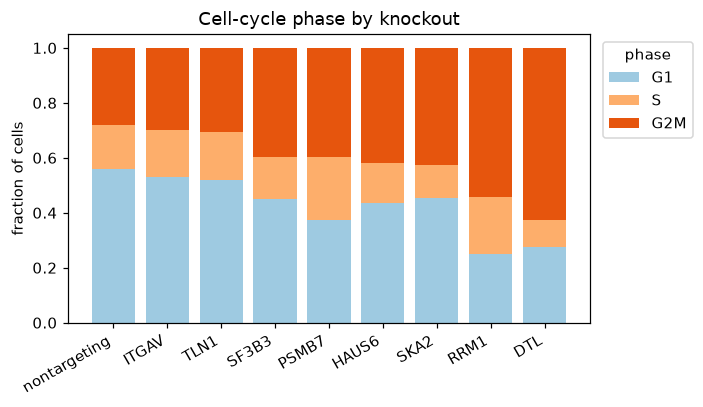

In [7]:
cells_file = pooch.retrieve(
    "https://exampledata.scverse.org/mantispy/aconcagua/aconcagua_cells.h5ad",
    known_hash="sha256:fcc65da402b2954d55c1b99bd0b944ed64d8550555ecdfaeb6e42dd7d68eb0ac",
    fname="aconcagua_cells.h5ad",
)
cells = ad.read_h5ad(cells_file)
mt.tl.cell_cycle_phase(cells, dna_feature="Nuclei_Intensity_IntegratedIntensity_DAPI", by="Metadata_Plate")
phase = pd.crosstab(cells.obs["Metadata_Gene"], cells.obs["Metadata_CellCyclePhase"], normalize="index")
phase = phase[["G1", "S", "G2M"]].sort_values("G2M")
fig, ax = plt.subplots(figsize=(6.5, 3.8))
bottom = np.zeros(len(phase))
for col, color in zip(["G1", "S", "G2M"], ["#9ecae1", "#fdae6b", "#e6550d"], strict=True):
    ax.bar(phase.index, phase[col], bottom=bottom, color=color, label=col)
    bottom += phase[col].to_numpy()
ax.set_ylabel("fraction of cells")
ax.set_title("Cell-cycle phase by knockout")
ax.legend(title="phase", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
fig.tight_layout()
plt.show()

The arrest is visible in the cells themselves. A spindle-gene knockout (HAUS6) caught in mitosis shows the
disorganized tubulin and condensed DNA of a cell that cannot divide, the pixels behind the G2M bar above.

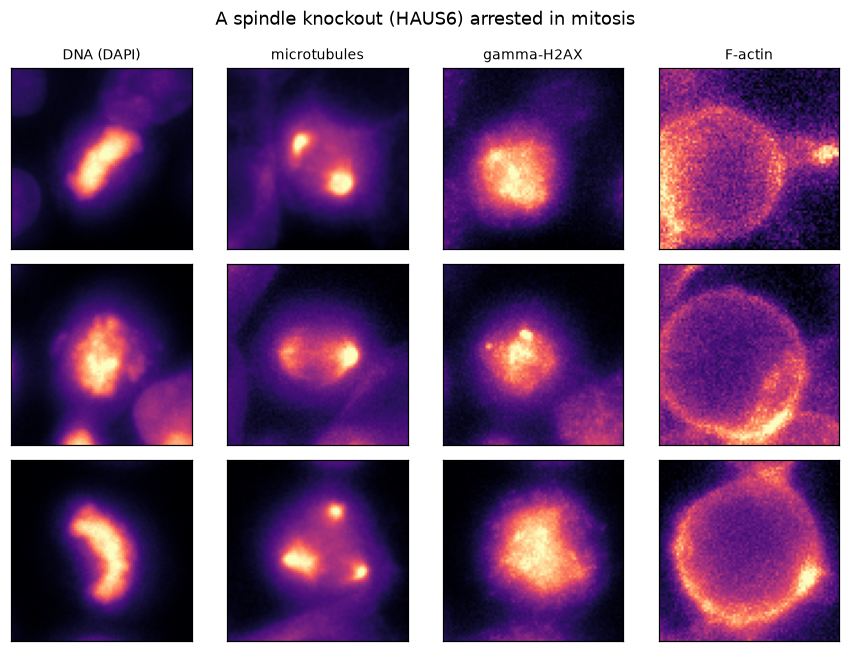

In [8]:
show_cells(example_cells("HAUS6", n=3, phase="mitotic"), "A spindle knockout (HAUS6) arrested in mitosis")

# The phenotypic landscape

The subset was a worked example of calling hits honestly. The reason to run a screen this size is the map it draws.
With all 5,299 genes measured in the same four channels, genes that do the same job look alike, and that similarity,
computed from pixels alone, turns out to recover the cell's known machinery. The published gene-level profiles carry
the whole landscape, so the rest of this page works from them.

In [9]:
published = ad.read_h5ad(
    pooch.retrieve(
        "https://ops-explorer-public.s3.amazonaws.com/aconcagua/aconcagua/visualizations/interphase/aggregated_data.h5ad",
        known_hash="sha256:f55756939edc8ddf108092d88c4efe248765b4db4ec39322d4b4a988e04af929",
        fname="brief_interphase.h5ad",
    )
)
land = ad.AnnData(
    X=np.nan_to_num(np.asarray(published.X, dtype="float32")),
    obs=pd.DataFrame(
        {
            "Metadata_Gene": published.obs_names.astype(str),
            "cluster": published.obs["cluster_group_1"].astype(str).values,
        },
        index=published.obs_names.astype(str),
    ),
    var=published.var.copy(),
)
land.obsm["X_phate"] = np.asarray(published.obsm["X_phate"])
mt.tl.similarity(land, metric="pearson")  # gene x gene correlation in land.obsp["similarity"]
land

AnnData object with n_obs × n_vars = 5299 × 76
    obs: 'Metadata_Gene', 'cluster'
    var: 'feature_name', 'feature_type', 'compartment'
    uns: 'mantispy'
    obsm: 'X_phate'
    obsp: 'similarity'
    layers: None (.X)

## Genes in the same complex look alike

Protein complexes are the sharpest test, because their subunits act as one machine, so knocking out any member gives
the same phenotype. {func}`~mantispy.tl.pathway_coherence` measures it: for each CORUM complex it compares the mean
similarity among its members against random gene groups of the same size. Ordering the most coherent complexes by
membership turns the correlation matrix into blocks, and seen as distributions their subunits correlate several
times more tightly than random gene pairs.

CORUM complexes with 4+ members measured: 292; coherent at q < 0.05: 129


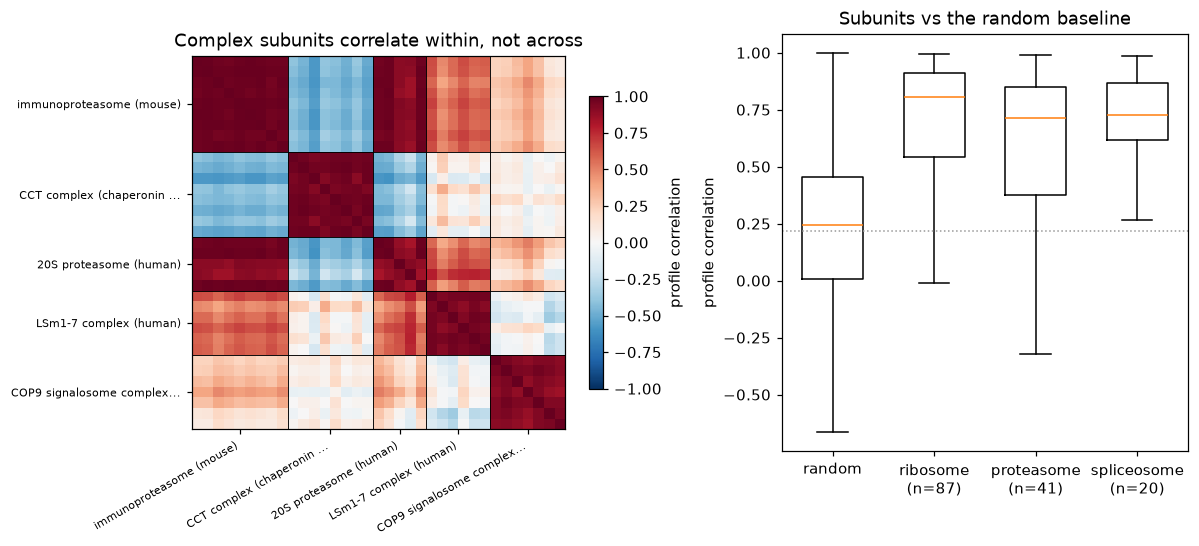

In [10]:
# CORUM protein complexes (Enrichr export), as a source -> target net of complex -> member gene.
corum_gmt = pooch.retrieve(
    "https://maayanlab.cloud/Enrichr/geneSetLibrary?mode=text&libraryName=CORUM",
    known_hash="sha256:b16c8cf235f5fc528f01a5c02aaf3681f74396a3affca5509e98f3ff6d0f2677",
    fname="corum_enrichr.gmt",
)
rows = []
for line in open(corum_gmt):
    parts = line.rstrip("\n").split("\t")
    if len(parts) < 3:
        continue
    for g in parts[2:]:
        g = g.split(",")[0].strip()
        if g:
            rows.append((parts[0], g.upper()))
corum = pd.DataFrame(rows, columns=["source", "target"]).drop_duplicates()
corum["weight"] = 1.0
present = set(land.obs_names)
comp = {
    c: grp["target"].unique().tolist() for c, grp in corum.groupby("source") if grp["target"].isin(present).sum() >= 3
}
comp = {c: [g for g in ms if g in present] for c, ms in comp.items()}

mt.tl.pathway_coherence(land, corum, gene_key="Metadata_Gene", min_genes=4, n_permutations=1000, seed=SEED)
pc = pd.DataFrame(land.uns["mantispy"]["pathway_coherence"])
print(f"CORUM complexes with 4+ members measured: {len(pc)}; coherent at q < 0.05: {int((pc['qvalue'] < 0.05).sum())}")

pos = {g: i for i, g in enumerate(land.obs_names)}
S = land.obsp["similarity"]
top_sets = pc[(pc["n_genes"] >= 6) & (pc["n_genes"] <= 20)].sort_values("coherence", ascending=False)["set"].head(5)
members, bounds, labels = [], [0], []
for cx in top_sets:
    gs = [g for g in sorted(comp[cx]) if g not in members]
    if len(gs) < 4:
        continue
    members += gs
    bounds.append(len(members))
    labels.append(cx if len(cx) < 26 else cx[:24] + "...")
block = S[np.ix_([pos[g] for g in members], [pos[g] for g in members])]

fig, axes = plt.subplots(1, 2, figsize=(11, 5), gridspec_kw={"width_ratios": [1.15, 1]})
im = axes[0].imshow(block, cmap="RdBu_r", vmin=-1, vmax=1)
for b in bounds[1:-1]:
    axes[0].axhline(b - 0.5, color="k", lw=0.6)
    axes[0].axvline(b - 0.5, color="k", lw=0.6)
ticks = [(bounds[i] + bounds[i + 1]) / 2 - 0.5 for i in range(len(labels))]
axes[0].set_xticks(ticks, labels, rotation=30, ha="right", fontsize=7)
axes[0].set_yticks(ticks, labels, fontsize=7)
fig.colorbar(im, ax=axes[0], shrink=0.7, label="profile correlation")
axes[0].set_title("Complex subunits correlate within, not across")

rng = np.random.default_rng(SEED)
random_pairs = S[rng.integers(0, S.shape[0], 20000), rng.integers(0, S.shape[0], 20000)]
families = {"ribosome": ("RPL", "RPS"), "proteasome": ("PSM",), "spliceosome": ("SNRP", "SF3")}
data, names = [random_pairs], ["random"]
for name, pref in families.items():
    m = [pos[g] for g in land.obs_names if str(g).startswith(pref)]
    sub_s = S[np.ix_(m, m)]
    data.append(sub_s[np.triu_indices(len(m), 1)])
    names.append(f"{name}\n(n={len(m)})")
axes[1].boxplot(data, tick_labels=names, showfliers=False, widths=0.6)
axes[1].axhline(float(np.mean(random_pairs)), color="0.6", ls=":", lw=1)
axes[1].set_ylabel("profile correlation")
axes[1].set_title("Subunits vs the random baseline")
fig.tight_layout()
plt.show()

Well over a hundred of the measured complexes are coherent beyond chance. The published screen also groups the genes
into clusters by morphology alone; testing each cluster against CORUM with a hypergeometric test names them. Clusters
built from pixels line up with real machinery, with no sequence or annotation used to build them.

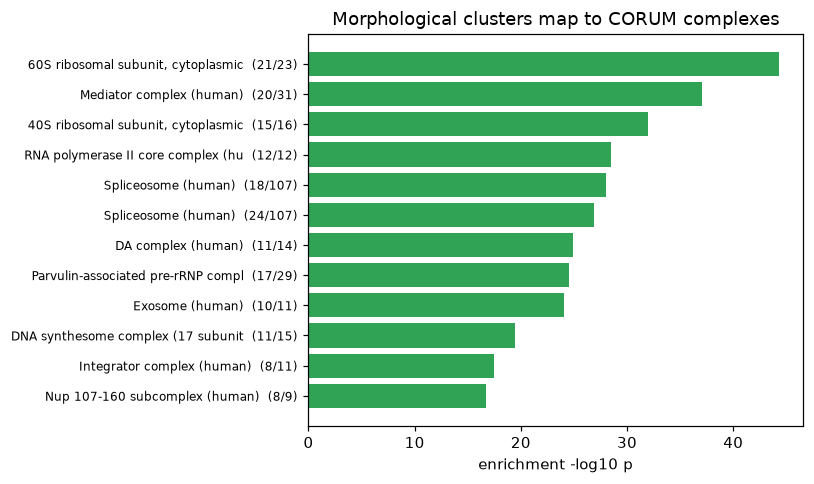

In [11]:
from scipy.stats import hypergeom

n_all = land.n_obs
in_corum = {g for ms in comp.values() for g in ms}
gene_to_comp = {}
for c, ms in comp.items():
    for g in ms:
        gene_to_comp.setdefault(g, []).append(c)


def _dominant_complex(members):
    counts = {}
    for g in members:
        for c in gene_to_comp.get(g, []):
            counts[c] = counts.get(c, 0) + 1
    best = None
    for c, k in counts.items():
        if k < 4:
            continue
        p = float(hypergeom.sf(k - 1, n_all, len(comp[c]), len(members)))
        if best is None or p < best[1]:
            best = (c, p, k, len(comp[c]))
    return best


rows = []
for cl, size in land.obs["cluster"].value_counts().items():
    if size < 20:
        continue
    members = list(land.obs_names[(land.obs["cluster"] == cl).to_numpy()])
    best = _dominant_complex(members)
    if best and best[1] < 1e-4:
        rows.append((cl, len(members), best[0], best[2], best[3], -np.log10(max(best[1], 1e-300))))
modules = pd.DataFrame(rows, columns=["cluster", "n", "complex", "k", "size", "neglog10p"]).sort_values("neglog10p")
tab = modules.tail(12)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.barh(range(len(tab)), tab["neglog10p"], color="#31a354")
ax.set_yticks(
    range(len(tab)),
    [f"{c[:34]}  ({k}/{s})" for c, k, s in zip(tab["complex"], tab["k"], tab["size"], strict=True)],
    fontsize=8,
)
ax.set_xlabel("enrichment -log10 p")
ax.set_title("Morphological clusters map to CORUM complexes")
fig.tight_layout()
plt.show()

## Placing genes of unknown function

This is what the landscape is for. A cluster dominated by a complex also contains genes that are **not** CORUM
members of it. If morphology tracks function, those genes are candidate partners of the machine their cluster names.
Taking the best-named clusters and their non-member genes, mantispy places each candidate against the complex: its
correlation to the known members sits at the members' own level, far above random.

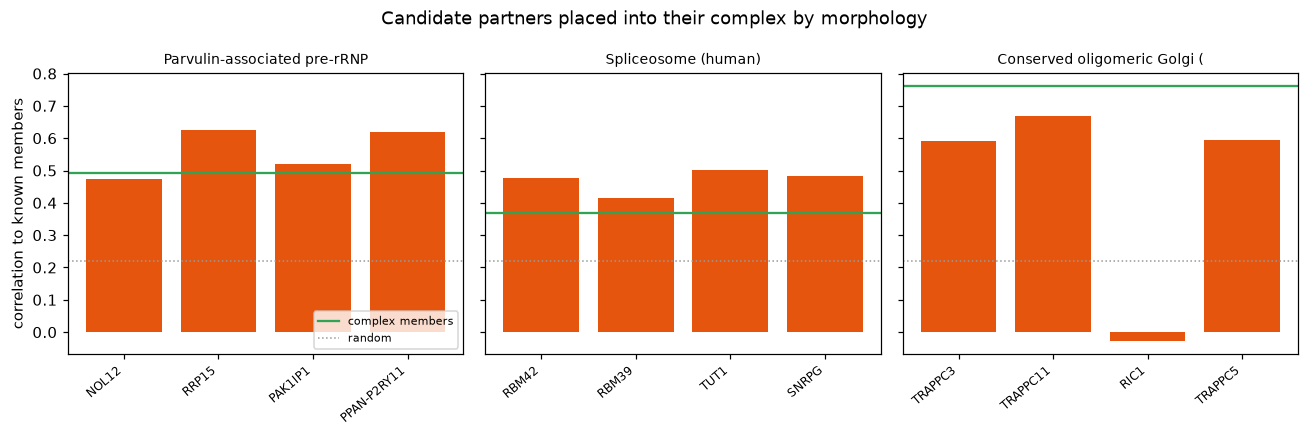

Parvulin-associated pre-rRNP complex (mo: candidates ['NOL12', 'RRP15', 'PAK1IP1', 'PPAN-P2RY11']
Spliceosome (human): candidates ['RBM42', 'RBM39', 'TUT1', 'SNRPG']
Conserved oligomeric Golgi (COG) complex: candidates ['TRAPPC3', 'TRAPPC11', 'RIC1', 'TRAPPC5']


In [12]:
# Prefer complexes whose non-member candidates are not trivially named like the complex (e.g. rRNA processing,
# splicing and Golgi factors), which makes the prediction a real one rather than an obvious re-labelling.
WANT = ["rRNP", "Spliceosome", "COG", "exosome", "Integrator", "Mediator", "Nup", "proteasome"]
picks, used = [], set()
ranked = modules.sort_values("neglog10p", ascending=False)
for key in WANT:
    for _, r in ranked.iterrows():
        if key.lower() not in r["complex"].lower() or r["complex"] in used:
            continue
        members = list(land.obs_names[(land.obs["cluster"] == r["cluster"]).to_numpy()])
        cand = [g for g in members if g not in in_corum]
        known = [g for g in comp[r["complex"]] if g in pos]
        if len(cand) >= 3 and len(known) >= 4:
            picks.append((r["complex"], known, cand[:4]))
            used.add(r["complex"])
            break
    if len(picks) == 3:
        break

fig, axes = plt.subplots(1, len(picks), figsize=(4 * len(picks), 4), sharey=True)
for ax, (cx, known, cand) in zip(np.atleast_1d(axes), picks, strict=True):
    ki = [pos[g] for g in known]
    base = float(np.mean(random_pairs))
    member_level = float(np.mean([S[np.ix_(ki, ki)][np.triu_indices(len(ki), 1)]]))
    vals = [float(np.mean([S[pos[g], j] for j in ki])) for g in cand]
    ax.axhline(member_level, color="#31a354", ls="-", lw=1.5, label="complex members")
    ax.axhline(base, color="0.6", ls=":", lw=1, label="random")
    ax.bar(range(len(cand)), vals, color="#e6550d")
    ax.set_xticks(range(len(cand)), cand, rotation=40, ha="right", fontsize=8)
    ax.set_title(cx[:28], fontsize=9)
axes[0].set_ylabel("correlation to known members")
axes[0].legend(fontsize=7, loc="lower right")
fig.suptitle("Candidate partners placed into their complex by morphology")
fig.tight_layout()
plt.show()
for cx, _known, cand in picks:
    print(f"{cx[:40]}: candidates {cand}")

The candidates are not noise. The ribosome-biogenesis cluster pulls in rRNA-processing factors, the spliceosome
cluster pulls in splicing factors, and so on, genes a biologist would assign to the same machine, reached from
morphology with no prior knowledge. This is how an OPS puts a function on an uncharacterized gene.

## Machines, not programs

Not every gene set behaves this way. The broad transcriptional programs of the MSigDB hallmark collection, which
group genes by co-expression rather than by a shared physical machine, are barely coherent in morphology. The screen
sees what cells are built from, not what they transcribe. The same holds as a single retrieval number: across every
CORUM pair, correlation separates complex co-members from random genes above chance (though the genome-wide figure
mixes the tight machines with large, loose complexes that dilute it).

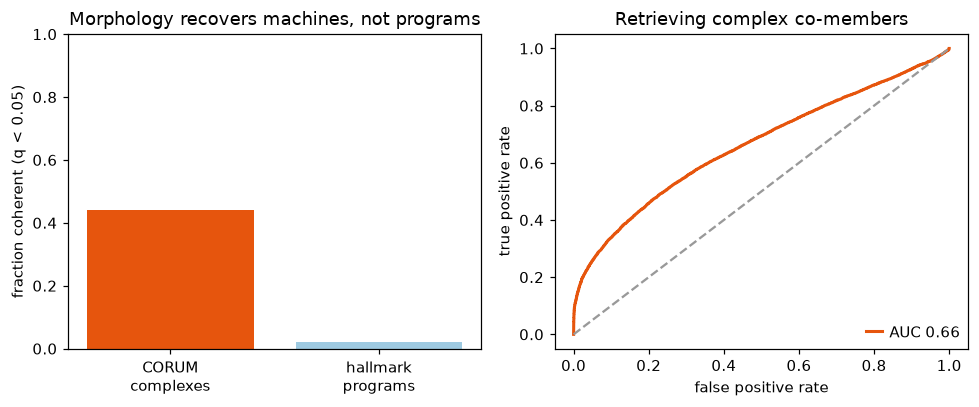

In [13]:
from sklearn.metrics import roc_auc_score, roc_curve

hallmark = mt.tl.gene_set_network("hallmark")
mt.tl.pathway_coherence(
    land,
    hallmark,
    gene_key="Metadata_Gene",
    min_genes=5,
    n_permutations=1000,
    seed=SEED,
    key_added="pathway_coherence_hallmark",
)
ph = pd.DataFrame(land.uns["mantispy"]["pathway_coherence_hallmark"])

pairs = set()
for members in comp.values():
    idx = [pos[g] for g in members]
    for a in range(len(idx)):
        for b in range(a + 1, len(idx)):
            pairs.add((min(idx[a], idx[b]), max(idx[a], idx[b])))
pos_pairs = list(pairs)
rng.shuffle(pos_pairs)
pos_pairs = pos_pairs[:20000]
neg = set()
while len(neg) < len(pos_pairs):
    a, b = int(rng.integers(0, S.shape[0])), int(rng.integers(0, S.shape[0]))
    if a != b:
        neg.add((min(a, b), max(a, b)))
neg_pairs = list(neg)[: len(pos_pairs)]
y = np.r_[np.ones(len(pos_pairs)), np.zeros(len(neg_pairs))]
score = np.r_[[S[a, b] for a, b in pos_pairs], [S[a, b] for a, b in neg_pairs]]
auc = roc_auc_score(y, score)
fpr, tpr, _ = roc_curve(y, score)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
axes[0].bar(
    ["CORUM\ncomplexes", "hallmark\nprograms"],
    [(pc["qvalue"] < 0.05).mean(), (ph["qvalue"] < 0.05).mean()],
    color=["#e6550d", "#9ecae1"],
)
axes[0].set_ylabel("fraction coherent (q < 0.05)")
axes[0].set_ylim(0, 1)
axes[0].set_title("Morphology recovers machines, not programs")
axes[1].plot(fpr, tpr, color="#e6550d", lw=2, label=f"AUC {auc:.2f}")
axes[1].plot([0, 1], [0, 1], "--", color="0.6")
axes[1].set_xlabel("false positive rate")
axes[1].set_ylabel("true positive rate")
axes[1].set_title("Retrieving complex co-members")
axes[1].legend(loc="lower right")
fig.tight_layout()
plt.show()

## What to take away

- In a pooled screen the guide is the unit and the well is the replicate.
- A non-targeting null measures the effect of cutting; unexpressed genes measure what lies beyond it, and the
  difference is most of the random-gene calls.
- The features say which channels a knockout moved, and the single cells say which cell states it acted on.
- At screen scale, morphological similarity recovers protein complexes, the ribosome, proteasome and spliceosome
  among them, and places uncharacterized genes into the machines they resemble. That recovery is the evidence that
  the phenotypes mean something.